# NB24 — Why Least Squares? Gauss–Markov, MLE and Numerical Stability

> **StatQuest principle: we didn't pick "sum of squared residuals" because it looks nice — two theorems say it is the best choice, and good numerics make sure the computer actually finds it.**

---

## The main ideas are:

1. **Gauss–Markov theorem:** under linearity, exogeneity (E[ε|X]=0), homoscedasticity and no autocorrelation
   (plus full-rank X), OLS is **BLUE** — the Best (lowest-variance) Linear Unbiased Estimator
2. **Normality is NOT required** for BLUE — it is only needed for exact small-sample t/F tests
3. **MLE:** if errors are Gaussian, maximising the likelihood is *exactly* minimising SSR → OLS = MLE
4. If the assumptions fail, OLS can lose its crown (WLS/GLS more efficient) or become biased
5. **Numerics:** never invert $X^TX$. It squares the condition number. Use QR or SVD (`np.linalg.lstsq`)


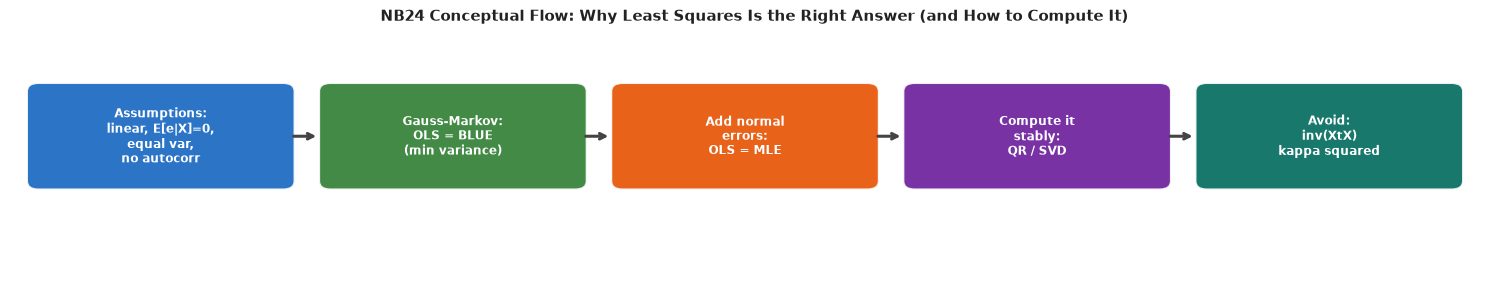

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

def flow_diagram(steps, title, colors=None, notes=None, figsize=(14, 2.8)):
    """Draw a horizontal flow diagram.  steps = list of strings."""
    n = len(steps)
    default_colors = [
        '#1565C0','#2E7D32','#E65100','#6A1B9A',
        '#00695C','#AD1457','#37474F','#4E342E',
        '#0277BD','#558B2F',
    ]
    colors = (colors or default_colors[:n]) + default_colors
    notes  = notes or [''] * n

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.3, n * 3.1)
    ax.set_ylim(-1.2, 2.4)
    ax.axis('off')

    bw, bh = 2.6, 1.3
    for i, (step, color, note) in enumerate(zip(steps, colors, notes)):
        x = i * 3.1
        box = FancyBboxPatch((x, 0.2), bw, bh,
                             boxstyle="round,pad=0.12",
                             facecolor=color, edgecolor='white', linewidth=1.5, alpha=0.90)
        ax.add_patch(box)
        ax.text(x + bw/2, 0.2 + bh/2, step,
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold', multialignment='center')
        if note:
            ax.text(x + bw/2, 0.02, note,
                    ha='center', va='top', fontsize=7, color='#555', style='italic')
        if i < n - 1:
            ax.annotate('',
                xy=(x + bw + 0.38, 0.2 + bh/2),
                xytext=(x + bw + 0.08, 0.2 + bh/2),
                arrowprops=dict(arrowstyle='->', color='#444', lw=2.2))

    ax.set_title(title, fontsize=11, fontweight='bold', pad=6, color='#222')
    plt.tight_layout(pad=0.4)
    plt.show()

flow_diagram(
    steps=[
        'Assumptions:\nlinear, E[e|X]=0,\nequal var,\nno autocorr',
        'Gauss-Markov:\nOLS = BLUE\n(min variance)',
        'Add normal\nerrors:\nOLS = MLE',
        'Compute it\nstably:\nQR / SVD',
        'Avoid:\ninv(XtX)\nkappa squared',
    ],
    title='NB24 Conceptual Flow: Why Least Squares Is the Right Answer (and How to Compute It)',
    figsize=(15, 2.8),
)


## Step 1 — Gauss–Markov: OLS beats any other linear unbiased estimator

Any estimator of the form $\tilde b = Cy$ with $CX = I$ is linear and unbiased.
Gauss–Markov says $Var(\tilde b_j) \ge Var(\hat b_j^{OLS})$.

**Competitor:** the "two-group slope" — split the data at the median x and use
$\tilde b_1 = (\bar y_{high} - \bar y_{low}) / (\bar x_{high} - \bar x_{low})$.
It is linear in y and unbiased. We simulate 10,000 datasets with **non-normal** (uniform) errors to show
normality is not needed.


In [2]:
import numpy as np

rng = np.random.default_rng(24)
n, reps = 40, 10000
x = np.linspace(0, 10, n)
X = np.column_stack([np.ones(n), x])
hi = x > np.median(x)
b_ols, b_grp = [], []
for _ in range(reps):
    eps = rng.uniform(-3, 3, n)                      # NON-normal errors, mean 0, equal variance
    y = 1 + 2 * x + eps
    b_ols.append(np.linalg.lstsq(X, y, rcond=None)[0][1])
    b_grp.append((y[hi].mean() - y[~hi].mean()) / (x[hi].mean() - x[~hi].mean()))
b_ols, b_grp = np.array(b_ols), np.array(b_grp)
print("True slope = 2.0, errors ~ Uniform(-3, 3)  (not normal!)\n")
print(f"OLS slope       : mean = {b_ols.mean():.4f}   variance = {b_ols.var():.5f}")
print(f"Two-group slope : mean = {b_grp.mean():.4f}   variance = {b_grp.var():.5f}")
print(f"\nBoth unbiased. OLS variance is {b_grp.var()/b_ols.var():.2f}x smaller -> OLS is 'Best'")


True slope = 2.0, errors ~ Uniform(-3, 3)  (not normal!)

OLS slope       : mean = 1.9982   variance = 0.00843
Two-group slope : mean = 1.9978   variance = 0.01127

Both unbiased. OLS variance is 1.34x smaller -> OLS is 'Best'


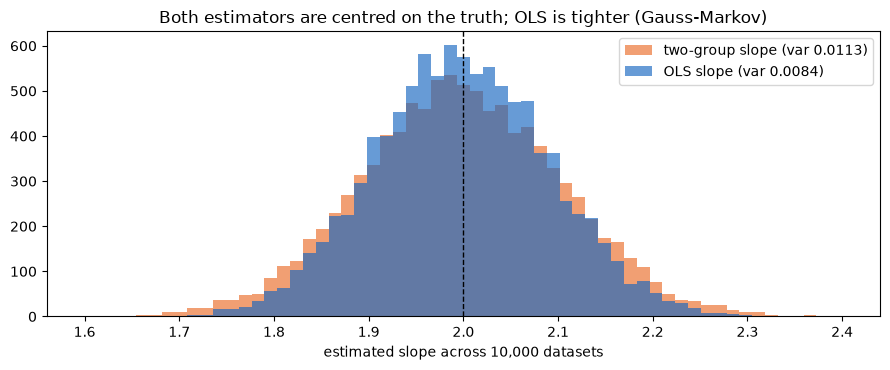

In [3]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(1.6, 2.4, 60)
ax.hist(b_grp, bins=bins, alpha=0.55, color='#E65100', label=f'two-group slope (var {b_grp.var():.4f})')
ax.hist(b_ols, bins=bins, alpha=0.65, color='#1565C0', label=f'OLS slope (var {b_ols.var():.4f})')
ax.axvline(2, color='k', ls='--', lw=1)
ax.set_xlabel('estimated slope across 10,000 datasets'); ax.legend()
ax.set_title('Both estimators are centred on the truth; OLS is tighter (Gauss-Markov)')
plt.tight_layout(); plt.show()


## Step 2 — When an assumption breaks, OLS is no longer "best"

With **heteroscedastic** errors (sd grows with x), OLS is still unbiased but **WLS** (weights $1/\sigma_i^2$) has lower variance.
This is why NB06's statement "OLS is still the best among linear models when assumptions break" is not correct.


In [4]:
import numpy as np

rng = np.random.default_rng(241)
sd = 0.3 + 0.6 * x                                    # error sd grows with x
W = 1 / sd ** 2
b_o, b_w = [], []
for _ in range(reps):
    y = 1 + 2 * x + rng.normal(0, sd)
    b_o.append(np.linalg.lstsq(X, y, rcond=None)[0][1])
    sw = np.sqrt(W)
    b_w.append(np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)[0][1])
b_o, b_w = np.array(b_o), np.array(b_w)
print("Heteroscedastic errors (sd = 0.3 + 0.6x):")
print(f"  OLS slope: mean = {b_o.mean():.4f}, variance = {b_o.var():.5f}")
print(f"  WLS slope: mean = {b_w.mean():.4f}, variance = {b_w.var():.5f}")
print(f"  -> both unbiased, WLS variance {b_o.var()/b_w.var():.2f}x smaller: Gauss-Markov's 'equal variance' assumption matters")


Heteroscedastic errors (sd = 0.3 + 0.6x):
  OLS slope: mean = 1.9979, variance = 0.04999
  WLS slope: mean = 1.9987, variance = 0.01613
  -> both unbiased, WLS variance 3.10x smaller: Gauss-Markov's 'equal variance' assumption matters


## Step 3 — Maximum likelihood: Gaussian noise ⇒ OLS

If $y_i = b_0 + b_1x_i + \varepsilon_i$ with $\varepsilon_i \sim N(0,\sigma^2)$, the log-likelihood is

$$\ell(b,\sigma) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\underbrace{\sum (y_i - b_0 - b_1x_i)^2}_{SSR}$$

For any fixed σ, maximising ℓ means **minimising SSR**. So the MLE of b is the OLS estimate,
and the MLE of σ² is SSR/n (biased; OLS reports the unbiased SSR/(n−2)).
We check numerically by maximising ℓ with `scipy.optimize.minimize` — no least-squares formula used.


In [5]:
import numpy as np
from scipy.optimize import minimize
import statsmodels.api as sm

rng = np.random.default_rng(242)
y = 1 + 2 * x + rng.normal(0, 2, n)

def neg_loglik(theta):
    b0, b1, log_sigma = theta
    s2 = np.exp(2 * log_sigma)
    r = y - b0 - b1 * x
    return 0.5 * n * np.log(2 * np.pi * s2) + 0.5 * np.sum(r ** 2) / s2

mle = minimize(neg_loglik, x0=[0.0, 0.0, 0.0], method='BFGS')
ols = sm.OLS(y, X).fit()
ssr = np.sum(ols.resid ** 2)
print(f"MLE (numerical optimiser): b0 = {mle.x[0]:.5f}  b1 = {mle.x[1]:.5f}  sigma^2 = {np.exp(2*mle.x[2]):.5f}")
print(f"OLS (closed form)        : b0 = {ols.params[0]:.5f}  b1 = {ols.params[1]:.5f}")
print(f"SSR / n       = {ssr/n:.5f}   <- MLE of sigma^2 (biased)")
print(f"SSR / (n - 2) = {ssr/(n-2):.5f}   <- what OLS reports (unbiased)")
print(f"\nMax log-likelihood = {-mle.fun:.4f}   statsmodels llf = {ols.llf:.4f}")
print("This is the 'Log-Likelihood' line in every statsmodels summary (NB05, NB08).")


MLE (numerical optimiser): b0 = 0.72929  b1 = 2.14691  sigma^2 = 4.06279
OLS (closed form)        : b0 = 0.72929  b1 = 2.14691
SSR / n       = 4.06279   <- MLE of sigma^2 (biased)
SSR / (n - 2) = 4.27662   <- what OLS reports (unbiased)

Max log-likelihood = -84.7949   statsmodels llf = -84.7949
This is the 'Log-Likelihood' line in every statsmodels summary (NB05, NB08).


## Step 4 — Computing OLS stably: normal equations vs QR vs SVD

The normal equations solve $(X^TX)b = X^Ty$. But $\kappa(X^TX) = \kappa(X)^2$: every digit of
ill-conditioning in X is **doubled**. With float64 (~16 digits), κ(X) ≈ 10⁸ leaves almost nothing.

- **QR:** $X = QR$, solve $Rb = Q^Ty$ — works with κ(X), not κ(X)²
- **SVD / `np.linalg.lstsq`:** most robust; also handles rank-deficient X (pseudo-inverse)

Test: a polynomial design $x, x^2, …, x^{p}$ on x ∈ [1, 2] — columns nearly identical. True coefficients all = 1.


In [6]:
import numpy as np
import warnings

rng = np.random.default_rng(243)
xx = np.linspace(1, 2, 200)
print(f"{'degree':>6} {'cond(X)':>10} {'cond(XtX)':>10} | {'max coef error':>45}")
print(f"{'':>6} {'':>10} {'':>10} | {'inv(XtX)':>11} {'solve(XtX)':>11} {'QR':>10} {'lstsq/SVD':>10}")
for p in [3, 6, 9, 12]:
    Xp = np.vander(xx, p + 1, increasing=True)
    b_true = np.ones(p + 1)
    yy = Xp @ b_true                                  # noise-free: the exact answer is all ones
    XtX = Xp.T @ Xp
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        e_inv = np.abs(np.linalg.inv(XtX) @ Xp.T @ yy - b_true).max()
        e_solve = np.abs(np.linalg.solve(XtX, Xp.T @ yy) - b_true).max()
    Q, R = np.linalg.qr(Xp)
    e_qr = np.abs(np.linalg.solve(R, Q.T @ yy) - b_true).max()
    e_svd = np.abs(np.linalg.lstsq(Xp, yy, rcond=None)[0] - b_true).max()
    print(f"{p:>6} {np.linalg.cond(Xp):>10.1e} {np.linalg.cond(XtX):>10.1e} | "
          f"{e_inv:>11.1e} {e_solve:>11.1e} {e_qr:>10.1e} {e_svd:>10.1e}")
print("\ncond(XtX) = cond(X)^2. The normal-equation errors blow up first; QR and SVD stay accurate far longer.")


degree    cond(X)  cond(XtX) |                                max coef error
                             |    inv(XtX)  solve(XtX)         QR  lstsq/SVD
     3    2.4e+03    5.6e+06 |     3.8e-10     3.4e-10    6.4e-15    1.5e-13
     6    1.1e+07    1.2e+14 |     3.6e-02     2.1e-03    2.5e-10    1.1e-10
     9    6.2e+10    1.0e+18 |     3.8e+03     4.1e+01    9.1e-07    3.6e-07
    12    3.8e+14    3.6e+20 |     2.6e+05     2.3e+02    1.1e-03    3.0e-05

cond(XtX) = cond(X)^2. The normal-equation errors blow up first; QR and SVD stay accurate far longer.


## Key Takeaways

| Result | Needs | Says |
|---|---|---|
| **Gauss–Markov (BLUE)** | linearity, E[ε\|X]=0, equal variance, no autocorrelation, full rank | OLS has the smallest variance among linear unbiased estimators |
| — | **not** normality | uniform errors in Step 1 still give OLS the win |
| Broken equal variance | heteroscedastic errors | OLS still unbiased, but WLS is more efficient (Step 2) |
| **MLE** | Gaussian errors | maximising likelihood = minimising SSR → OLS = MLE; σ²_MLE = SSR/n |
| **Numerics** | — | κ(XᵀX) = κ(X)²: avoid `inv(XtX)`; use QR or `np.linalg.lstsq` (SVD) — sklearn and statsmodels already do |

**Correction to NB06:** when assumptions break, OLS is *not* automatically "the best among linear models":
heteroscedasticity/autocorrelation → GLS/WLS is more efficient; broken linearity or exogeneity → OLS is biased.
